# RadioSkySim — Guia completo do contexto `skymap`

Este notebook executa, documenta e integra as funcionalidades disponíveis nas camadas **Domain**, **Application** e **Infrastructure** do contexto `skymap`.

Fluxos cobertos:

- `NSide` e `SkyMapDataset`;
- entidade `SkyMap`;
- máscaras, transformações e análise científica;
- factory;
- casos de uso de geração, análise e survey contínuo;
- adapters Healpy, PySM3 e HiPS;
- visualização, FITS, cache, download e telemetria;
- fluxo integrado end-to-end.

> Kernel esperado: **Python (radiosky)**.

## 1. Configuração de execução

As opções abaixo permitem controlar integrações que dependem de rede ou de dados externos. Para a validação completa, mantenha todas como `True`.

In [73]:
from __future__ import annotations

import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Localiza a raiz que contém src/radioskysims."""
    candidates = (start, *start.parents)
    for candidate in candidates:
        if (candidate / "src" / "radioskysims").is_dir():
            return candidate
    raise RuntimeError(
        "Não foi possível localizar a raiz do RadioSkySim. "
        "Abra o notebook dentro do repositório."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "skymap_howto"
CACHE_DIR = OUTPUT_DIR / "cache"
HIPS_PROVIDER_DIR = OUTPUT_DIR / "hips_provider"

for directory in (OUTPUT_DIR, CACHE_DIR, HIPS_PROVIDER_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RUN_NETWORK = True
RUN_INTERACTIVE_ALADIN = True
RUN_PYSM = True

NSIDE_DEMO = 16
NSIDE_DOWNGRADED = 8
FREQUENCY_GHZ = 30.0
RANDOM_SEED = 20260721

print("Projeto:", PROJECT_ROOT)
print("Python:", sys.executable)
print("Saídas:", OUTPUT_DIR)
print("Kernel radiosky:", "radiosky" in sys.executable.lower())

Projeto: /home/usu-rio/Documentos/github/RadioSkySim
Python: /home/usu-rio/yes/envs/radiosky/bin/python
Saídas: /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto
Kernel radiosky: True


## 2. Dependências e versões

In [75]:
from importlib.metadata import PackageNotFoundError, version

PACKAGES = (
    "numpy",
    "healpy",
    "matplotlib",
    "astropy",
    "xarray",
    "dask",
    "requests",
    "astroquery",
    "ipyaladin",
    "reproject",
    "pysm3",
)

versions: dict[str, str] = {}
for package in PACKAGES:
    try:
        versions[package] = version(package)
    except PackageNotFoundError:
        versions[package] = "não instalado"

for package, package_version in versions.items():
    print(f"{package:12s}: {package_version}")

numpy       : 1.26.4
healpy      : 1.19.0
matplotlib  : 3.10.8
astropy     : 6.1.7
xarray      : 2023.12.0
dask        : 2026.7.1
requests    : 2.32.5
astroquery  : 0.4.11
ipyaladin   : 0.8.0
reproject   : 0.21.0
pysm3       : 3.4.2


## 3. Imports do projeto e dependências científicas

In [76]:
from collections.abc import Sequence
from contextlib import suppress
from time import perf_counter
from typing import Any

import dask.array as da
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import requests
import xarray as xr

from astropy.coordinates import Angle, Latitude, Longitude, SkyCoord
from astropy.io import fits
from astropy.visualization import AsinhStretch, ImageNormalize, PercentileInterval
from astropy.wcs import WCS
from dask import delayed
from IPython.display import display

from radioskysims.application.skymap.analyze import AnalyzeSkyMapUseCase
from radioskysims.application.skymap.dto import (
    AnalyzeSkyMapInputDTO,
    GenerateSkyMapInputDTO,
)
from radioskysims.application.skymap.generate import (
    ContinuumSurveyMapUseCase,
    GenerateSkyMapUseCase,
)
from radioskysims.application.skymap.ports import (
    SkyMapAnalyzerPort,
    SkyMapGeneratorPort,
)
from radioskysims.domain.skymap import NSide, SkyMap, SkyMapAnalysis, SkyMapDataset
from radioskysims.domain.skymap.factory import SkyMapFactory
from radioskysims.domain.skymap.mask import SkyMask
from radioskysims.domain.skymap.operations import SkyMapOperations
from radioskysims.infrastructure.skymap.adapters.analysis import HealpySkyMapAnalyzer
from radioskysims.infrastructure.skymap.adapters.visualization import SkyMapVisualizer
from radioskysims.infrastructure.skymap.io import (
    CacheContext,
    CacheStore,
    HybridCache,
    SkyMapCacheKeyGenerator,
    cacheable,
)
from radioskysims.infrastructure.skymap.io.download import FileDownloader
from radioskysims.infrastructure.skymap.telemetry import Telemetry
from radioskysims.infrastructure.skymap.utils import (
    ensure_float_array,
    expected_npix,
    mask_invalid,
    validate_healpix_map,
)

OPTIONAL_IMPORT_ERRORS: dict[str, str] = {}

try:
    from astroquery.hips2fits import hips2fits
except Exception as exc:
    hips2fits = None
    OPTIONAL_IMPORT_ERRORS["astroquery.hips2fits"] = repr(exc)

try:
    from ipyaladin import Aladin
except Exception as exc:
    Aladin = None
    OPTIONAL_IMPORT_ERRORS["ipyaladin"] = repr(exc)

try:
    from radioskysims.infrastructure.skymap.providers.healpy import HealpySkyMapProvider
except Exception as exc:
    HealpySkyMapProvider = None
    OPTIONAL_IMPORT_ERRORS["HealpySkyMapProvider"] = repr(exc)

try:
    from radioskysims.infrastructure.skymap.providers.hips import HiPSSkyMapProvider
except Exception as exc:
    HiPSSkyMapProvider = None
    OPTIONAL_IMPORT_ERRORS["HiPSSkyMapProvider"] = repr(exc)

try:
    from radioskysims.infrastructure.skymap.providers.pysm import PySMSkyMapGeneratorAdapter
except Exception as exc:
    PySMSkyMapGeneratorAdapter = None
    OPTIONAL_IMPORT_ERRORS["PySMSkyMapGeneratorAdapter"] = repr(exc)

print("Imports centrais concluídos.")
if OPTIONAL_IMPORT_ERRORS:
    print("Integrações opcionais indisponíveis:")
    for name, error in OPTIONAL_IMPORT_ERRORS.items():
        print(f"- {name}: {error}")

Imports centrais concluídos.


## 4. Funções auxiliares do notebook

In [78]:
RESULTS: dict[str, bool] = {}
DETAILS: dict[str, str] = {}


def register(name: str, success: bool, detail: str = "") -> None:
    RESULTS[name] = bool(success)
    DETAILS[name] = detail
    icon = "OK" if success else "FALHOU"
    print(f"[{icon}] {name}" + (f" — {detail}" if detail else ""))


def summarize_skymap(skymap: SkyMap, name: str = "SkyMap") -> dict[str, Any]:
    data = skymap.data
    finite = np.isfinite(data)
    summary = {
        "name": name,
        "nside": skymap.nside_value,
        "npix": skymap.npix,
        "unit": skymap.unit,
        "frame": skymap.frame,
        "freq_ghz": skymap.freq_ghz,
        "field": skymap.field,
        "finite_pixels": int(finite.sum()),
        "finite_fraction": float(finite.mean()),
        "min": float(np.nanmin(data)) if finite.any() else np.nan,
        "max": float(np.nanmax(data)) if finite.any() else np.nan,
        "mean": float(np.nanmean(data)) if finite.any() else np.nan,
    }
    return summary


def print_summary(summary: dict[str, Any]) -> None:
    for key, value in summary.items():
        print(f"{key:16s}: {value}")


def make_analytic_map(nside: NSide, amplitude: float = 1.0) -> np.ndarray:
    """Mapa determinístico suave para demonstrações reproduzíveis."""
    theta, phi = hp.pix2ang(nside.value, np.arange(nside.npix))
    signal = (
        2.7
        + 0.35 * np.cos(theta)
        + 0.15 * np.sin(theta) ** 2 * np.cos(2.0 * phi)
        + 0.05 * np.sin(3.0 * phi) * np.sin(theta)
    )
    return np.asarray(amplitude * signal, dtype=np.float64)


def error_record(label: str, callable_obj: Any) -> tuple[str, str]:
    try:
        callable_obj()
    except Exception as exc:
        return label, f"{type(exc).__name__}: {exc}"
    return label, "NENHUM ERRO"

# Parte I — Domain

## 5. `NSide`

`NSide` é um Value Object: valida o valor HEALPix e fornece o número esperado de pixels.

In [79]:
nside = NSide(NSIDE_DEMO)
nside_down = NSide(NSIDE_DOWNGRADED)

print("NSide:", nside)
print("Valor:", nside.value)
print("Npix:", nside.npix)
print("Npix pelo helper:", expected_npix(nside))

assert nside.npix == 12 * NSIDE_DEMO**2
assert expected_npix(nside) == nside.npix
assert nside == NSide(NSIDE_DEMO)
assert hash(nside) == hash(NSide(NSIDE_DEMO))

register("domain.nside", True, f"nside={nside.value}, npix={nside.npix}")

NSide: NSide(16)
Valor: 16
Npix: 3072
Npix pelo helper: 3072
[OK] domain.nside — nside=16, npix=3072


In [80]:
invalid_nside_examples = [
    error_record("texto", lambda: NSide("16")),
    error_record("zero", lambda: NSide(0)),
    error_record("não potência de 2", lambda: NSide(3)),
]

for label, result in invalid_nside_examples:
    print(f"{label:20s} -> {result}")

assert all(result != "NENHUM ERRO" for _, result in invalid_nside_examples)
register("domain.nside_validation", True)

texto                -> InvalidNSideError: NSide deve ser um inteiro
zero                 -> InvalidNSideError: NSide deve ser >= 1
não potência de 2    -> InvalidNSideError: NSide deve ser potência de 2 (healpy)
[OK] domain.nside_validation


## 6. `SkyMapDataset`: NumPy, Xarray, Dask Array e Dask Delayed

In [81]:
base_array = make_analytic_map(nside)

numpy_dataset = SkyMapDataset(base_array)
print("NumPy:", numpy_dataset.shape, numpy_dataset.ndim, numpy_dataset.size)
np.testing.assert_allclose(numpy_dataset.to_numpy(), base_array)

xarray_dataset = SkyMapDataset(
    xr.DataArray(base_array, dims=("pixel",), name="temperature")
)
print("Xarray:", xarray_dataset.shape, xarray_dataset.ndim, xarray_dataset.size)
np.testing.assert_allclose(xarray_dataset.to_numpy(), base_array)

xarray_dask_dataset = SkyMapDataset(
    xr.DataArray(
        da.from_array(base_array, chunks=nside.npix // 4),
        dims=("pixel",),
        name="temperature_lazy",
    )
)
print(
    "Xarray+Dask:",
    xarray_dask_dataset.shape,
    xarray_dask_dataset.ndim,
    xarray_dask_dataset.size,
)
np.testing.assert_allclose(xarray_dask_dataset.to_numpy(), base_array)

dask_dataset = SkyMapDataset(
    da.from_array(base_array, chunks=nside.npix // 4)
)
print("Dask Array:", dask_dataset.shape, dask_dataset.ndim, dask_dataset.size)
np.testing.assert_allclose(dask_dataset.to_numpy(), base_array)

@delayed
def delayed_map() -> np.ndarray:
    return base_array.copy()

lazy_dataset = SkyMapDataset(delayed_map())
print("Dask Delayed:", lazy_dataset.shape, lazy_dataset.ndim, lazy_dataset.size)
assert lazy_dataset.shape is None
assert lazy_dataset.ndim is None
assert lazy_dataset.size is None
np.testing.assert_allclose(lazy_dataset.to_numpy(), base_array)

register("domain.skymap_dataset", True, "4 backends validados")

NumPy: (3072,) 1 3072
Xarray: (3072,) 1 3072
Xarray+Dask: (3072,) 1 3072
Dask Array: (3072,) 1 3072
Dask Delayed: None None None
[OK] domain.skymap_dataset — 4 backends validados


## 7. Entidade `SkyMap`

In [82]:
skymap = SkyMap.from_array(
    data=base_array,
    nside=nside,
    unit="K",
    frame="galactic",
    freq_ghz=FREQUENCY_GHZ,
    field="I",
)

print(skymap)
print_summary(summarize_skymap(skymap, "analytic_map"))

assert skymap.nside == nside
assert skymap.npix == nside.npix
assert len(skymap) == nside.npix
assert skymap.data.dtype == np.float64
assert skymap.dataset.size == nside.npix

register("domain.skymap_entity", True)

SkyMap(nside=16, npix=3072, unit='K', frame='galactic', field='I')
name            : analytic_map
nside           : 16
npix            : 3072
unit            : K
frame           : galactic
freq_ghz        : 30.0
field           : I
finite_pixels   : 3072
finite_fraction : 1.0
min             : 2.3355138652719476
max             : 3.0572816106286216
mean            : 2.7000000000000006
[OK] domain.skymap_entity


In [83]:
# A propriedade data entrega uma cópia defensiva.
external_copy = skymap.data
original_first_pixel = skymap.data[0]
external_copy[0] = -999.0
assert skymap.data[0] == original_first_pixel

# copy() cria outra entidade com dados independentes.
skymap_copy = skymap.copy()
assert skymap_copy == skymap
assert skymap_copy is not skymap
assert skymap_copy.dataset is not skymap.dataset
assert hash(skymap_copy) == hash(skymap)

print("repr:", repr(skymap_copy))
register("domain.skymap_copy_equality", True)

repr: SkyMap(nside=16, npix=3072, unit='K', frame='galactic', field='I')
[OK] domain.skymap_copy_equality


## 8. `SkyMapFactory`

In [84]:
factory = SkyMapFactory(
    unit="K",
    frame="galactic",
    field="I",
)

factory_map = factory.create(
    dataset=base_array,
    nside=nside,
    freq_ghz=FREQUENCY_GHZ,
)

assert factory_map == skymap
print(factory_map)
register("domain.factory", True)

SkyMap(nside=16, npix=3072, unit='K', frame='galactic', field='I')
[OK] domain.factory


## 9. Transformada harmônica: `alm()` e `from_alm()`

A reconstrução limitada por `lmax` preserva a estrutura de baixa frequência angular do mapa.

In [85]:
LMAX_DEMO = min(3 * nside.value - 1, 47)

alm = skymap.alm(lmax=LMAX_DEMO)
reconstructed_map = SkyMap.from_alm(
    alm=alm,
    nside=nside,
    unit=skymap.unit,
    frame=skymap.frame,
    freq_ghz=skymap.freq_ghz,
    field=skymap.field,
)

reconstruction_error = reconstructed_map.data - skymap.data

print("Quantidade de alm:", alm.size)
print("Erro RMS da reconstrução:", np.sqrt(np.mean(reconstruction_error**2)))

assert np.iscomplexobj(alm)
assert reconstructed_map.npix == skymap.npix
assert np.all(np.isfinite(reconstructed_map.data))

register("domain.alm_roundtrip", True, f"lmax={LMAX_DEMO}")

Quantidade de alm: 1176
Erro RMS da reconstrução: 0.0011693259414913022
[OK] domain.alm_roundtrip — lmax=47


## 10. Máscaras binária e ponderada

In [86]:
theta, _ = hp.pix2ang(nside.value, np.arange(nside.npix))
galactic_latitude_deg = 90.0 - np.degrees(theta)

binary_mask = (np.abs(galactic_latitude_deg) >= 20.0).astype(np.float64)
weighted_mask = np.clip((np.abs(galactic_latitude_deg) - 10.0) / 20.0, 0.0, 1.0)

masked_array = SkyMask.apply(skymap.data, binary_mask)
weighted_array = SkyMask.apply(skymap.data, weighted_mask)
masked_entity = skymap.apply_mask(binary_mask)

np.testing.assert_allclose(masked_entity.data, masked_array)
assert not np.shares_memory(masked_array, skymap.data)
assert binary_mask.shape == skymap.data.shape
assert weighted_mask.shape == skymap.data.shape

print("Fração preservada pela máscara binária:", binary_mask.mean())
print("Peso médio da máscara ponderada:", weighted_mask.mean())

register("domain.mask", True)

Fração preservada pela máscara binária: 0.6458333333333334
Peso médio da máscara ponderada: 0.6601238317211977
[OK] domain.mask


## 11. Operações: suavização, rotação e downgrade

In [87]:
FWHM_DEG = 3.0
FWHM_RAD = np.deg2rad(FWHM_DEG)

smoothed_data = SkyMapOperations.smooth(
    skymap.data,
    fwhm_rad=FWHM_RAD,
)

downgraded_data = SkyMapOperations.downgrade(
    skymap.data,
    target_nside=nside_down,
)

assert smoothed_data.shape == skymap.data.shape
assert downgraded_data.size == nside_down.npix
assert np.all(np.isfinite(smoothed_data))
assert np.all(np.isfinite(downgraded_data))

smoothed_map = SkyMap.from_array(
    smoothed_data,
    nside=nside,
    unit=skymap.unit,
    frame=skymap.frame,
    freq_ghz=skymap.freq_ghz,
    field=skymap.field,
)

downgraded_map = SkyMap.from_array(
    downgraded_data,
    nside=nside_down,
    unit=skymap.unit,
    frame=skymap.frame,
    freq_ghz=skymap.freq_ghz,
    field=skymap.field,
)

register("domain.smooth", True, f"FWHM={FWHM_DEG} deg")
register("domain.downgrade", True, f"{nside.value} -> {nside_down.value}")

[OK] domain.smooth — FWHM=3.0 deg
[OK] domain.downgrade — 16 -> 8


In [88]:
# Validação real da implementação de domínio. A célula não interrompe o
# restante do guia caso a versão instalada do healpy seja incompatível
# com o argumento rot usado pela implementação atual.
rotation_angles_rad = tuple(np.deg2rad([15.0, 5.0, 0.0]))
rotated_domain_map: SkyMap | None = None

try:
    rotated_domain_data = SkyMapOperations.rotate(
        skymap.data,
        rot=rotation_angles_rad,
    )
    rotated_domain_map = SkyMap.from_array(
        rotated_domain_data,
        nside=nside,
        unit=skymap.unit,
        frame=skymap.frame,
        freq_ghz=skymap.freq_ghz,
        field=skymap.field,
    )
    register("domain.rotate", True)
except Exception as exc:
    register(
        "domain.rotate",
        False,
        f"{type(exc).__name__}: {exc}",
    )

[FALHOU] domain.rotate — TypeError: rotate_alm() got an unexpected keyword argument 'rot'


## 12. Estatísticas e espectro angular

In [89]:
mean_value = SkyMapAnalysis.mean(skymap.data)
rms_value = SkyMapAnalysis.rms(skymap.data)
min_value, max_value = SkyMapAnalysis.min_max(skymap.data)
cls_domain = SkyMapAnalysis.angular_power_spectrum(
    skymap.data,
    lmax=LMAX_DEMO,
)

print("Média:", mean_value)
print("RMS:", rms_value)
print("Mínimo:", min_value)
print("Máximo:", max_value)
print("C_l shape:", cls_domain.shape)

assert min_value <= mean_value <= max_value
assert rms_value >= 0.0
assert cls_domain.ndim == 1
assert cls_domain.size == LMAX_DEMO + 1
assert np.all(np.isfinite(cls_domain))

register("domain.analysis", True)

Média: 2.7000000000000006
RMS: 2.7088102165402086
Mínimo: 2.3355138652719476
Máximo: 3.0572816106286216
C_l shape: (48,)
[OK] domain.analysis


# Parte II — Application

## 13. `GenerateSkyMapUseCase` com adapter analítico determinístico

Este adapter local implementa a porta da Application e permite validar a orquestração sem depender de downloads externos.

In [90]:
class AnalyticSkyMapGenerator(SkyMapGeneratorPort):
    def generate(
        self,
        *,
        nside: NSide,
        freq_ghz: float,
        components: Sequence[str] | None = None,
    ) -> SkyMap:
        component_count = len(components or ())
        amplitude = 1.0 + 0.1 * component_count
        return SkyMap.from_array(
            make_analytic_map(nside, amplitude=amplitude),
            nside=nside,
            unit="K",
            frame="galactic",
            freq_ghz=freq_ghz,
            field="I",
        )


analytic_generator = AnalyticSkyMapGenerator()
generate_use_case = GenerateSkyMapUseCase(generator=analytic_generator)

generate_input = GenerateSkyMapInputDTO(
    frequency_ghz=FREQUENCY_GHZ,
    nside=NSIDE_DEMO,
    components=("synchrotron", "dust"),
)

generate_output = generate_use_case.execute(generate_input)

assert generate_output.nside == NSIDE_DEMO
assert generate_output.npix == nside.npix
assert generate_output.map_data.shape == (nside.npix,)

application_generated_map = SkyMap.from_array(
    generate_output.map_data,
    nside=nside,
    unit="K",
    frame="galactic",
    freq_ghz=FREQUENCY_GHZ,
    field="I",
)

print_summary(summarize_skymap(application_generated_map, "application_generated"))
register("application.generate_use_case", True)

name            : application_generated
nside           : 16
npix            : 3072
unit            : K
frame           : galactic
freq_ghz        : 30.0
field           : I
finite_pixels   : 3072
finite_fraction : 1.0
min             : 2.802616638326337
max             : 3.668737932754346
mean            : 3.24
[OK] application.generate_use_case


## 14. `AnalyzeSkyMapUseCase` com adapter Healpy

In [91]:
healpy_analyzer = HealpySkyMapAnalyzer()
analyze_use_case = AnalyzeSkyMapUseCase(analyzer=healpy_analyzer)

analyze_input = AnalyzeSkyMapInputDTO(
    sky_map=application_generated_map,
    lmax=LMAX_DEMO,
)

analyze_output = analyze_use_case.execute(analyze_input)

assert analyze_output.nside == NSIDE_DEMO
assert analyze_output.lmax == LMAX_DEMO
assert analyze_output.cls.shape == (LMAX_DEMO + 1,)

np.testing.assert_allclose(
    analyze_output.cls,
    hp.anafast(application_generated_map.data, lmax=LMAX_DEMO),
)

register("application.analyze_use_case", True)

[OK] application.analyze_use_case


## 15. Integração opcional com PySM3

A execução pode exigir dados auxiliares do PySM3. Falhas de rede ou ausência desses dados são registradas sem interromper o restante do notebook.

In [92]:
pysm_generated_map: SkyMap | None = None

if not RUN_PYSM:
    register("infrastructure.pysm", False, "desativado por RUN_PYSM=False")
elif PySMSkyMapGeneratorAdapter is None:
    register(
        "infrastructure.pysm",
        False,
        OPTIONAL_IMPORT_ERRORS.get("PySMSkyMapGeneratorAdapter", "import indisponível"),
    )
else:
    try:
        pysm_adapter = PySMSkyMapGeneratorAdapter(unit="uK_CMB", field="I")
        pysm_use_case = GenerateSkyMapUseCase(generator=pysm_adapter)
        pysm_output = pysm_use_case.execute(
            GenerateSkyMapInputDTO(
                frequency_ghz=FREQUENCY_GHZ,
                nside=NSIDE_DEMO,
                components=("synchrotron",),
            )
        )
        pysm_generated_map = SkyMap.from_array(
            pysm_output.map_data,
            nside=NSide(pysm_output.nside),
            unit="uK_CMB",
            frame="galactic",
            freq_ghz=FREQUENCY_GHZ,
            field="I",
        )
        print_summary(summarize_skymap(pysm_generated_map, "pysm_synchrotron"))
        register("infrastructure.pysm", True)
    except Exception as exc:
        register("infrastructure.pysm", False, f"{type(exc).__name__}: {exc}")

name            : pysm_synchrotron
nside           : 16
npix            : 3072
unit            : uK_CMB
frame           : galactic
freq_ghz        : 30.0
field           : I
finite_pixels   : 3072
finite_fraction : 1.0
min             : 12.011745320359978
max             : 1504.7821223153228
mean            : 65.61489906257547
[OK] infrastructure.pysm


# Parte III — Infrastructure

## 16. Visualização de mapas e espectros

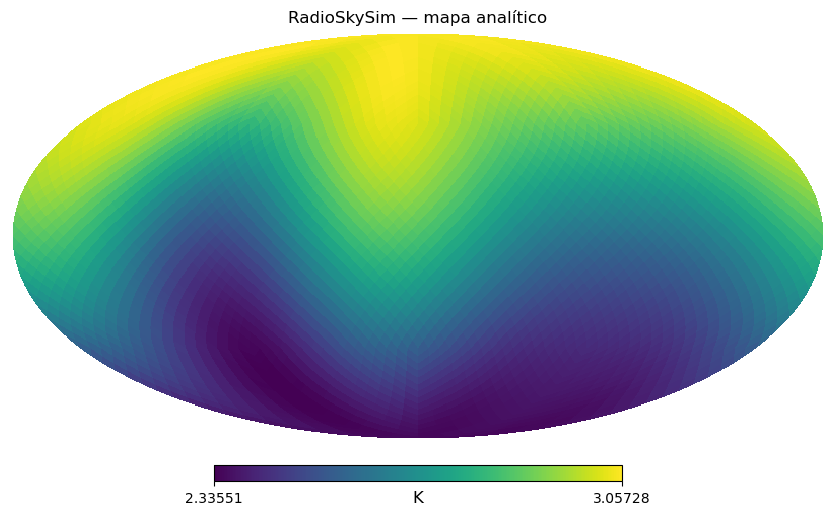

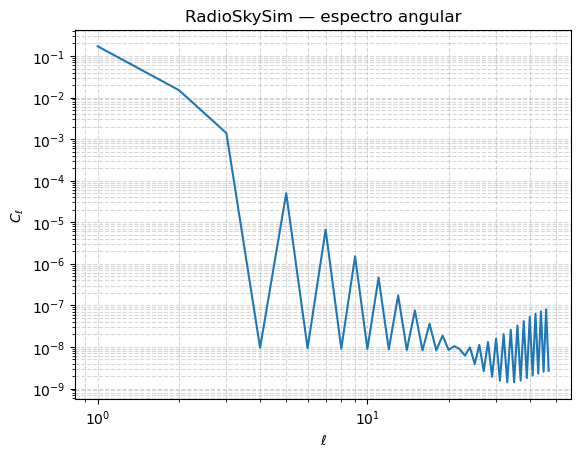

[OK] infrastructure.visualization — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/analytic_skymap.png


In [93]:
visualizer = SkyMapVisualizer()

visualizer.plot_map(
    skymap,
    title="RadioSkySim — mapa analítico",
    unit=skymap.unit,
    show=True,
)

visualizer.plot_cls(
    cls_domain,
    lmin=1,
    lmax=LMAX_DEMO,
    title="RadioSkySim — espectro angular",
    show=True,
)

map_png_path = OUTPUT_DIR / "analytic_skymap.png"
visualizer.save_map(
    skymap,
    str(map_png_path),
    title="RadioSkySim — mapa analítico",
    unit=skymap.unit,
)

assert map_png_path.exists()
assert map_png_path.stat().st_size > 0
register("infrastructure.visualization", True, str(map_png_path))

## 17. Helpers HEALPix de infraestrutura

In [94]:
validate_healpix_map(skymap.data, skymap.nside)

float_array = ensure_float_array(np.arange(12, dtype=np.int32))
assert float_array.dtype == np.float64

invalid_values = np.array([1.0, np.nan, np.inf, -np.inf], dtype=np.float64)
cleaned_values = mask_invalid(invalid_values, fill_value=-1.0)
np.testing.assert_array_equal(cleaned_values, np.array([1.0, -1.0, -1.0, -1.0]))

print("expected_npix:", expected_npix(skymap.nside))
print("cleaned_values:", cleaned_values)
register("infrastructure.utils", True)

expected_npix: 3072
cleaned_values: [ 1. -1. -1. -1.]
[OK] infrastructure.utils


## 18. FITS e transformações com `HealpySkyMapProvider`

In [95]:
healpy_provider = None
healpy_roundtrip_map: SkyMap | None = None
provider_rotated_map: SkyMap | None = None

if HealpySkyMapProvider is None:
    register(
        "infrastructure.healpy_provider",
        False,
        OPTIONAL_IMPORT_ERRORS.get("HealpySkyMapProvider", "import indisponível"),
    )
else:
    try:
        healpy_provider = HealpySkyMapProvider()
        healpy_fits_path = OUTPUT_DIR / "analytic_skymap_healpix.fits"

        healpy_provider.write_map(
            skymap,
            healpy_fits_path,
            overwrite=True,
        )

        healpy_roundtrip_map = healpy_provider.read_map(
            healpy_fits_path,
            unit=skymap.unit,
            frame=skymap.frame,
            field=skymap.field,
        )

        np.testing.assert_allclose(healpy_roundtrip_map.data, skymap.data)
        assert healpy_roundtrip_map.nside == skymap.nside

        header = healpy_provider.read_header(healpy_fits_path)
        print("FITS:", healpy_fits_path)
        print("Header NSIDE:", header.get("NSIDE"))

        provider_smoothed_map = healpy_provider.smooth(skymap, FWHM_RAD)
        provider_rotated_map = healpy_provider.rotate(skymap, rotation_angles_rad)
        provider_downgraded_map = healpy_provider.downgrade(skymap, nside_down)

        assert provider_smoothed_map.npix == skymap.npix
        assert provider_rotated_map.npix == skymap.npix
        assert provider_downgraded_map.npix == nside_down.npix

        register("infrastructure.healpy_provider", True, str(healpy_fits_path))
    except Exception as exc:
        register("infrastructure.healpy_provider", False, f"{type(exc).__name__}: {exc}")

setting the output map dtype to [dtype('float64')]


FITS: /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/analytic_skymap_healpix.fits
Header NSIDE: 16
[OK] infrastructure.healpy_provider — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/analytic_skymap_healpix.fits


## 19. Cache básico, híbrido e decorador `cacheable`

In [96]:
# CacheStore básico
basic_cache_dir = CACHE_DIR / "basic"
basic_cache = CacheStore(basic_cache_dir)
basic_cache.clear()

payload = {
    "frequency_ghz": FREQUENCY_GHZ,
    "nside": NSIDE_DEMO,
    "components": ["synchrotron", "dust"],
}
serialized_map = skymap.data.tobytes()

cached_path = basic_cache.save(payload, "bin", serialized_map)
assert basic_cache.exists(payload, "bin")
assert basic_cache.load(payload, "bin") == cached_path
assert cached_path.read_bytes() == serialized_map

print("Cache básico:", cached_path)
print("Entradas:", basic_cache.size())
print("Uso em MB:", basic_cache.disk_usage_mb())

# Cache híbrido
hybrid_cache = HybridCache(
    memory_max_size=4,
    disk_dir=CACHE_DIR / "hybrid",
)
hybrid_cache.clear()
key = SkyMapCacheKeyGenerator().generate(**payload)
hybrid_cache.set(key, serialized_map)
assert hybrid_cache.exists(key)
assert hybrid_cache.get(key) == serialized_map
print("Cache híbrido:", hybrid_cache.stats())

# Decorador transparente
CacheContext.set_cache(
    HybridCache(
        memory_max_size=4,
        disk_dir=CACHE_DIR / "decorator",
    )
)
CacheContext.clear()
CacheContext.enable()

call_counter = {"count": 0}

@cacheable(key_params=["frequency_ghz", "nside"], prefix="notebook")
def encoded_product(*, frequency_ghz: float, nside: int) -> bytes:
    call_counter["count"] += 1
    return f"{frequency_ghz}:{nside}".encode("utf-8")

first = encoded_product(frequency_ghz=FREQUENCY_GHZ, nside=NSIDE_DEMO)
second = encoded_product(frequency_ghz=FREQUENCY_GHZ, nside=NSIDE_DEMO)

assert first == second
assert call_counter["count"] == 1
print("CacheContext:", CacheContext.stats())

register("infrastructure.cache", True)

Cache básico: /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/cache/basic/581cde64e4040b30cc4a041e1a976668a50e125e34cfd195e185bb5167d07308.bin
Entradas: 1
Uso em MB: 0.0234375
Cache híbrido: {'memory_entries': 1, 'memory_mb': 0.0234375, 'disk_entries': 1, 'disk_mb': 0.0234375}
CacheContext: {'memory_entries': 1, 'memory_mb': 6.67572021484375e-06, 'disk_entries': 1, 'disk_mb': 6.67572021484375e-06}
[OK] infrastructure.cache


## 20. Telemetria estruturada

In [97]:
telemetry = Telemetry("notebook.skymap_howto")

with telemetry.measure("compute_demo_statistics"):
    demo_total = float(np.sum(skymap.data))

telemetry.event(
    "demo_statistics_ready",
    nside=skymap.nside_value,
    npix=skymap.npix,
    total=demo_total,
)

telemetry_stats = telemetry.stats()
telemetry_dump = telemetry.dump()

print("Stats:", telemetry_stats)
print("Eventos:", telemetry_dump["events"])

assert telemetry_stats["operations"] == 1
assert telemetry_stats["successful"] == 1
assert telemetry_stats["events"] == 1
register("infrastructure.telemetry", True)

Stats: {'operations': 1, 'successful': 1, 'failed': 0, 'total_time_ms': 0.07852300041122362, 'avg_time_ms': 0.07852300041122362, 'min_time_ms': 0.07852300041122362, 'max_time_ms': 0.07852300041122362, 'events': 1}
Eventos: [{'event': 'demo_statistics_ready', 'timestamp': 1784687460.5873632, 'metadata': {'nside': 16, 'npix': 3072, 'total': 8294.400000000001}}]
[OK] infrastructure.telemetry


# Parte IV — HiPS/NVSS

## 21. Configuração do catálogo

Catálogo testado: `https://casda.csiro.au/hips/NVSS/`.

In [98]:
HIPS_BASE_URL = "https://casda.csiro.au/hips/NVSS"
HIPS_PROPERTIES_URL = f"{HIPS_BASE_URL}/properties"
HIPS_ID = "CDS/P/NVSS"

RA_DEG = 180.0
DEC_DEG = 0.0
FOV_DEG = 2.0
CUTOUT_SIZE = 512

hips_properties: dict[str, str] = {}
hips_hdul: fits.HDUList | None = None
hips_cutout_data: np.ndarray | None = None
hips_cutout_wcs: WCS | None = None
hips_local_path: Path | None = None
continuum_skymap: SkyMap | None = None

## 22. Disponibilidade, download e metadados HiPS

In [99]:
def parse_hips_properties(content: str) -> dict[str, str]:
    properties: dict[str, str] = {}
    for raw_line in content.splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", maxsplit=1)
        properties[key.strip()] = value.strip()
    return properties


if not RUN_NETWORK:
    register("hips.properties", False, "rede desativada")
else:
    try:
        response = requests.get(HIPS_PROPERTIES_URL, timeout=30)
        response.raise_for_status()
        hips_properties = parse_hips_properties(response.text)

        selected_keys = (
            "creator_did",
            "obs_collection",
            "obs_title",
            "hips_frame",
            "hips_order",
            "hips_tile_width",
            "hips_tile_format",
            "hips_pixel_scale",
            "moc_sky_fraction",
        )
        for key in selected_keys:
            print(f"{key:20s}: {hips_properties.get(key)}")

        assert hips_properties
        assert hips_properties.get("obs_collection") == "NVSS"
        assert hips_properties.get("hips_frame") == "equatorial"
        assert "fits" in hips_properties.get("hips_tile_format", "")

        downloader = FileDownloader(timeout=30)
        properties_file = downloader.download(
            HIPS_PROPERTIES_URL,
            OUTPUT_DIR / "nvss_hips.properties",
            overwrite=True,
        )
        assert properties_file.read_text().strip()

        register("hips.properties", True, str(properties_file))
    except Exception as exc:
        register("hips.properties", False, f"{type(exc).__name__}: {exc}")

creator_did         : ivo://CDS/P/NVSS
obs_collection      : NVSS
obs_title           : NVSS - The NRAO VLA Sky Survey (intensity maps)
hips_frame          : equatorial
hips_order          : 5
hips_tile_width     : 512
hips_tile_format    : jpeg fits
hips_pixel_scale    : 0.003579
moc_sky_fraction    : 0.8242
[OK] hips.properties — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/nvss_hips.properties


## 23. Visualização interativa com Aladin Lite

In [100]:
aladin = None

if not RUN_INTERACTIVE_ALADIN:
    register("hips.aladin", False, "desativado")
elif Aladin is None:
    register(
        "hips.aladin",
        False,
        OPTIONAL_IMPORT_ERRORS.get("ipyaladin", "import indisponível"),
    )
else:
    try:
        target = SkyCoord(
            ra=RA_DEG * Angle(1, unit="deg"),
            dec=DEC_DEG * Angle(1, unit="deg"),
            frame="icrs",
        )
        aladin = Aladin(
            target=target,
            fov=Angle(FOV_DEG, unit="deg"),
            survey=HIPS_ID,
        )
        display(aladin)
        register("hips.aladin", True)
    except Exception as exc:
        register("hips.aladin", False, f"{type(exc).__name__}: {exc}")

[OK] hips.aladin


## 24. Recorte FITS com HiPS2FITS

In [101]:
if not RUN_NETWORK:
    register("hips.hips2fits", False, "rede desativada")
elif hips2fits is None:
    register(
        "hips.hips2fits",
        False,
        OPTIONAL_IMPORT_ERRORS.get("astroquery.hips2fits", "import indisponível"),
    )
else:
    try:
        hips2fits.timeout = 120
        hips_hdul = hips2fits.query(
            hips=HIPS_ID,
            width=CUTOUT_SIZE,
            height=CUTOUT_SIZE,
            projection="TAN",
            ra=Longitude(RA_DEG, unit="deg"),
            dec=Latitude(DEC_DEG, unit="deg"),
            fov=Angle(FOV_DEG, unit="deg"),
            coordsys="icrs",
            format="fits",
        )

        assert isinstance(hips_hdul, fits.HDUList)
        assert hips_hdul[0].data is not None

        hips_cutout_data = np.asarray(hips_hdul[0].data, dtype=np.float64)
        hips_cutout_wcs = WCS(hips_hdul[0].header)
        finite = np.isfinite(hips_cutout_data)

        print("Shape:", hips_cutout_data.shape)
        print("Pixels finitos:", int(finite.sum()), "/", hips_cutout_data.size)
        if finite.any():
            print("Mínimo:", np.nanmin(hips_cutout_data))
            print("Máximo:", np.nanmax(hips_cutout_data))
            print("Média:", np.nanmean(hips_cutout_data))

        assert hips_cutout_data.shape == (CUTOUT_SIZE, CUTOUT_SIZE)
        assert finite.any()

        hips_local_path = HIPS_PROVIDER_DIR / "NVSS.fits"
        hips_hdul.writeto(hips_local_path, overwrite=True)
        assert hips_local_path.exists()

        register("hips.hips2fits", True, str(hips_local_path))
    except Exception as exc:
        register("hips.hips2fits", False, f"{type(exc).__name__}: {exc}")

Shape: (512, 512)
Pixels finitos: 262144 / 262144
Mínimo: -0.002034605946391821
Máximo: 0.3029288649559021
Média: 0.00011719022181150365
[OK] hips.hips2fits — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/hips_provider/NVSS.fits


## 25. Visualização científica do recorte WCS

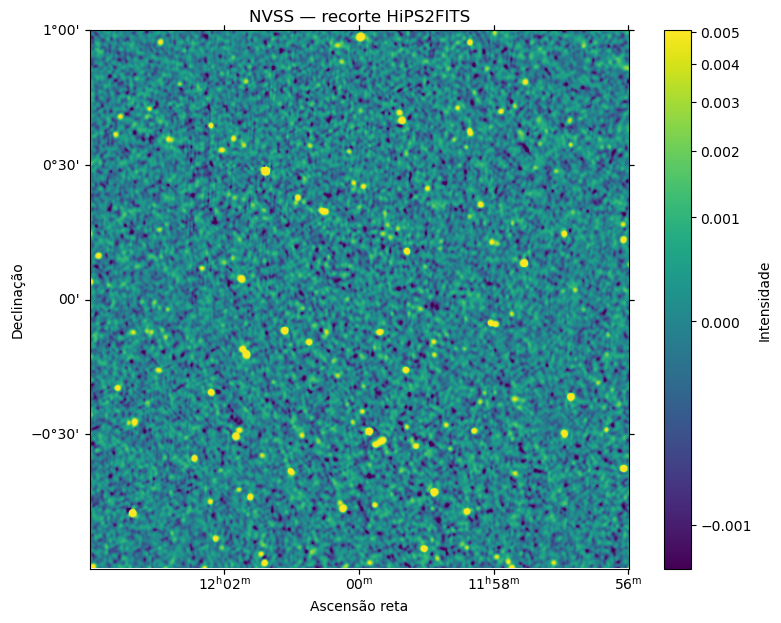

[OK] hips.wcs_plot — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/nvss_hips_cutout.png


In [102]:
if hips_cutout_data is None or hips_cutout_wcs is None:
    register("hips.wcs_plot", False, "cutout indisponível")
else:
    normalization = ImageNormalize(
        hips_cutout_data,
        interval=PercentileInterval(99.0),
        stretch=AsinhStretch(),
    )

    figure = plt.figure(figsize=(9, 7))
    axes = figure.add_subplot(111, projection=hips_cutout_wcs)
    image = axes.imshow(
        hips_cutout_data,
        origin="lower",
        norm=normalization,
    )
    axes.set_xlabel("Ascensão reta")
    axes.set_ylabel("Declinação")
    axes.set_title("NVSS — recorte HiPS2FITS")
    figure.colorbar(image, ax=axes, label="Intensidade")

    wcs_png_path = OUTPUT_DIR / "nvss_hips_cutout.png"
    figure.savefig(wcs_png_path, dpi=150, bbox_inches="tight")
    plt.show()

    assert wcs_png_path.exists()
    register("hips.wcs_plot", True, str(wcs_png_path))

## 26. `ContinuumSurveyMapUseCase` com `HiPSSkyMapProvider`

O provider atual usa um FITS local previamente obtido do HiPS e o reprojeta para HEALPix.

In [103]:
if HiPSSkyMapProvider is None:
    register(
        "application.continuum_use_case",
        False,
        OPTIONAL_IMPORT_ERRORS.get("HiPSSkyMapProvider", "import indisponível"),
    )
elif hips_local_path is None:
    register("application.continuum_use_case", False, "FITS NVSS indisponível")
else:
    try:
        hips_provider = HiPSSkyMapProvider(base_path=HIPS_PROVIDER_DIR)
        continuum_use_case = ContinuumSurveyMapUseCase(provider=hips_provider)

        continuum_skymap = continuum_use_case.execute(
            survey_id="NVSS",
            ra_deg=RA_DEG,
            dec_deg=DEC_DEG,
            fov_deg=FOV_DEG,
            nside=NSIDE_DEMO,
            freq_ghz=1.4,
            field="I",
        )

        assert isinstance(continuum_skymap, SkyMap)
        assert continuum_skymap.nside_value == NSIDE_DEMO
        assert continuum_skymap.npix == nside.npix

        print_summary(summarize_skymap(continuum_skymap, "nvss_healpix"))
        register("application.continuum_use_case", True)
    except Exception as exc:
        register(
            "application.continuum_use_case",
            False,
            f"{type(exc).__name__}: {exc}",
        )

[FALHOU] application.continuum_use_case — TypeError: reproject_to_healpix() got an unexpected keyword argument 'coord_system'


# Parte V — Fluxo end-to-end

## 27. Gerar → mascarar → suavizar → reduzir → analisar → visualizar → persistir

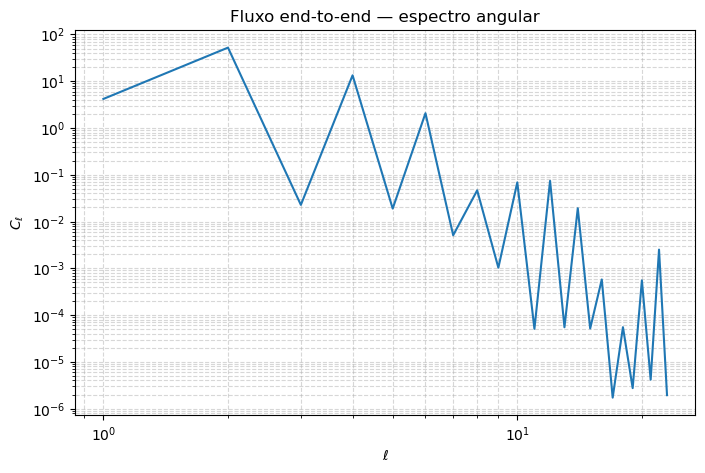

setting the output map dtype to [dtype('float64')]


name            : end_to_end
nside           : 8
npix            : 768
unit            : K
frame           : galactic
freq_ghz        : 40.0
field           : I
finite_pixels   : 768
finite_fraction : 1.0
min             : -0.01343132997036367
max             : 15.883980934569628
mean            : 9.268016776730027
[OK] end_to_end.pipeline


In [104]:
# 1. Geração pela Application
end_to_end_output = generate_use_case.execute(
    GenerateSkyMapInputDTO(
        frequency_ghz=40.0,
        nside=NSIDE_DEMO,
        components=("synchrotron", "dust", "cmb"),
    )
)

end_to_end_map = SkyMap.from_array(
    end_to_end_output.map_data,
    nside=NSide(end_to_end_output.nside),
    unit="K",
    frame="galactic",
    freq_ghz=40.0,
    field="I",
)

# 2. Máscara
end_to_end_masked = end_to_end_map.apply_mask(weighted_mask)

# 3. Limpeza defensiva e suavização
clean_masked_data = mask_invalid(end_to_end_masked.data, fill_value=0.0)
end_to_end_smoothed_data = SkyMapOperations.smooth(clean_masked_data, FWHM_RAD)

# 4. Downgrade
end_to_end_down_data = SkyMapOperations.downgrade(
    end_to_end_smoothed_data,
    nside_down,
)
end_to_end_down_map = SkyMap.from_array(
    end_to_end_down_data,
    nside=nside_down,
    unit=end_to_end_map.unit,
    frame=end_to_end_map.frame,
    freq_ghz=end_to_end_map.freq_ghz,
    field=end_to_end_map.field,
)

# 5. Análise pela Application
end_to_end_analysis = analyze_use_case.execute(
    AnalyzeSkyMapInputDTO(
        sky_map=end_to_end_down_map,
        lmax=min(3 * nside_down.value - 1, 23),
    )
)

# 6. Visualização e persistência
end_to_end_png = OUTPUT_DIR / "end_to_end_map.png"
visualizer.save_map(
    end_to_end_down_map,
    str(end_to_end_png),
    title="RadioSkySim — fluxo end-to-end",
    unit=end_to_end_down_map.unit,
)

end_to_end_cls_png = OUTPUT_DIR / "end_to_end_cls.png"
ell = np.arange(end_to_end_analysis.cls.size)
valid_ell = ell >= 1
plt.figure(figsize=(8, 5))
plt.loglog(ell[valid_ell], end_to_end_analysis.cls[valid_ell])
plt.xlabel(r"$\ell$")
plt.ylabel(r"$C_\ell$")
plt.title("Fluxo end-to-end — espectro angular")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.savefig(end_to_end_cls_png, dpi=150, bbox_inches="tight")
plt.show()

assert end_to_end_down_map.nside == nside_down
assert end_to_end_analysis.cls.ndim == 1
assert end_to_end_png.exists()
assert end_to_end_cls_png.exists()

end_to_end_fits: Path | None = None
if healpy_provider is not None:
    end_to_end_fits = OUTPUT_DIR / "end_to_end_map.fits"
    healpy_provider.write_map(
        end_to_end_down_map,
        end_to_end_fits,
        overwrite=True,
    )
    assert end_to_end_fits.exists()

print_summary(summarize_skymap(end_to_end_down_map, "end_to_end"))
register("end_to_end.pipeline", True)

## 28. Tratamento de erros representativos

In [70]:
error_examples = [
    error_record("NSide inválido", lambda: NSide(3)),
    error_record(
        "SkyMap com quantidade errada de pixels",
        lambda: SkyMap.from_array(
            np.ones(10),
            nside=NSide(1),
            unit="K",
        ),
    ),
    error_record(
        "Máscara com shape incompatível",
        lambda: SkyMask.apply(skymap.data, np.ones(3)),
    ),
    error_record(
        "Suavização com FWHM zero",
        lambda: SkyMapOperations.smooth(skymap.data, 0.0),
    ),
    error_record(
        "Análise com lmax inválido",
        lambda: SkyMapAnalysis.angular_power_spectrum(skymap.data, lmax=0),
    ),
]

if 'continuum_use_case' in globals():
    error_examples.append(
        error_record(
            "survey_id vazio",
            lambda: continuum_use_case.execute(
                survey_id=" ",
                ra_deg=0.0,
                dec_deg=0.0,
                fov_deg=1.0,
                nside=NSIDE_DEMO,
            ),
        )
    )

for label, result in error_examples:
    print(f"{label:38s} -> {result}")

assert all(result != "NENHUM ERRO" for _, result in error_examples)
register("error_handling", True, f"{len(error_examples)} casos")

NSide inválido                         -> InvalidNSideError: NSide deve ser potência de 2 (healpy)
SkyMap com quantidade errada de pixels -> InvalidDatasetError: Expected 12 pixels, received 10.
Máscara com shape incompatível         -> ValueError: map_data e mask devem possuir o mesmo shape
Suavização com FWHM zero               -> AnalysisError: fwhm_rad deve ser positivo
Análise com lmax inválido              -> ValueError: lmax deve ser positivo
survey_id vazio                        -> ValueError: survey_id não pode ser vazio
[OK] error_handling — 6 casos


## 29. Inventário de artefatos gerados

In [71]:
artifacts = sorted(path for path in OUTPUT_DIR.rglob("*") if path.is_file())

for path in artifacts:
    relative = path.relative_to(PROJECT_ROOT)
    print(f"{relative} — {path.stat().st_size} bytes")

assert map_png_path in artifacts
assert end_to_end_png in artifacts
assert end_to_end_cls_png in artifacts
register("artifacts.generated", True, f"{len(artifacts)} arquivos")

outputs/skymap_howto/analytic_skymap.png — 85679 bytes
outputs/skymap_howto/analytic_skymap_healpix.fits — 31680 bytes
outputs/skymap_howto/cache/basic/581cde64e4040b30cc4a041e1a976668a50e125e34cfd195e185bb5167d07308.bin — 24576 bytes
outputs/skymap_howto/cache/decorator/600a372bb889ca4b3dddf2e696e19abbd8b9effa0812e37ab3c9a0b312fc2943.bin — 7 bytes
outputs/skymap_howto/cache/decorator/600a372bb889ca4b3dddf2e696e19abbd8b9effa0812e37ab3c9a0b312fc2943.json — 191 bytes
outputs/skymap_howto/cache/hybrid/fbda0c92f1fc657a168fc6529b61648f7561f99940d314c37640f45c1adeadf5.bin — 24576 bytes
outputs/skymap_howto/cache/hybrid/fbda0c92f1fc657a168fc6529b61648f7561f99940d314c37640f45c1adeadf5.json — 185 bytes
outputs/skymap_howto/end_to_end_cls.png — 81584 bytes
outputs/skymap_howto/end_to_end_map.fits — 14400 bytes
outputs/skymap_howto/end_to_end_map.png — 43359 bytes
outputs/skymap_howto/hips_provider/NVSS.fits — 1054080 bytes
outputs/skymap_howto/nvss_hips.properties — 2162 bytes
outputs/skymap_how

## 30. Resumo final da execução

In [72]:
required_checks = (
    "domain.nside",
    "domain.nside_validation",
    "domain.skymap_dataset",
    "domain.skymap_entity",
    "domain.skymap_copy_equality",
    "domain.factory",
    "domain.alm_roundtrip",
    "domain.mask",
    "domain.smooth",
    "domain.downgrade",
    "domain.analysis",
    "application.generate_use_case",
    "application.analyze_use_case",
    "infrastructure.visualization",
    "infrastructure.utils",
    "infrastructure.cache",
    "infrastructure.telemetry",
    "end_to_end.pipeline",
    "error_handling",
    "artifacts.generated",
)

optional_checks = (
    "domain.rotate",
    "infrastructure.pysm",
    "infrastructure.healpy_provider",
    "hips.properties",
    "hips.aladin",
    "hips.hips2fits",
    "hips.wcs_plot",
    "application.continuum_use_case",
)

print("FUNCIONALIDADES OBRIGATÓRIAS")
for name in required_checks:
    print(f"[{'x' if RESULTS.get(name) else ' '}] {name}")

print("\nINTEGRAÇÕES/COMPATIBILIDADES")
for name in optional_checks:
    detail = DETAILS.get(name, "não executado")
    print(f"[{'x' if RESULTS.get(name) else ' '}] {name} — {detail}")

missing_required = [name for name in required_checks if not RESULTS.get(name, False)]
assert not missing_required, f"Falharam verificações obrigatórias: {missing_required}"

print("\nNotebook concluído. Verificações obrigatórias aprovadas.")

FUNCIONALIDADES OBRIGATÓRIAS
[x] domain.nside
[x] domain.nside_validation
[x] domain.skymap_dataset
[x] domain.skymap_entity
[x] domain.skymap_copy_equality
[x] domain.factory
[x] domain.alm_roundtrip
[x] domain.mask
[x] domain.smooth
[x] domain.downgrade
[x] domain.analysis
[x] application.generate_use_case
[x] application.analyze_use_case
[x] infrastructure.visualization
[x] infrastructure.utils
[x] infrastructure.cache
[x] infrastructure.telemetry
[x] end_to_end.pipeline
[x] error_handling
[x] artifacts.generated

INTEGRAÇÕES/COMPATIBILIDADES
[ ] domain.rotate — TypeError: rotate_alm() got an unexpected keyword argument 'rot'
[x] infrastructure.pysm — 
[x] infrastructure.healpy_provider — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/analytic_skymap_healpix.fits
[x] hips.properties — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skymap_howto/nvss_hips.properties
[x] hips.aladin — 
[x] hips.hips2fits — /home/usu-rio/Documentos/github/RadioSkySim/outputs/skyma

## Conclusão

Após executar **Restart Kernel and Run All Cells**, use o resumo acima para distinguir:

- funcionalidades centrais aprovadas;
- integrações opcionais executadas;
- incompatibilidades reais que exigem correção no código de produção, em vez de ajustes artificiais no notebook.